# Q2. Evaluate Reverse Polish Notation
You are given an array of strings tokens that represents an arithmetic expression in a Reverse Polish Notation.

Evaluate the expression. Return an integer that represents the value of the expression.

Note that:

The valid operators are '+', '-', '*', and '/'.
Each operand may be an integer or another expression.
The division between two integers always truncates toward zero.
There will not be any division by zero.
The input represents a valid arithmetic expression in a reverse polish notation.
The answer and all the intermediate calculations can be represented in a 32-bit integer.

In [8]:
class Solution {
    fun evalRPN(tokens: Array<String>): Int {
        val tokensMutable = tokens.toMutableList()

        val eval: (Int, Int, String) -> Int = { a, b, operator ->
            var result = 0

            when (operator) {
                "+" -> result = a + b
                "-" -> result = a - b
                "*" -> result = a * b
                "/" -> result = a / b
            }

            result
        }

        var result = tokensMutable[0].toInt()
        var i = 0

        while (i < tokensMutable.size){
            if (!tokensMutable[i].get(tokensMutable[i].length-1).isDigit() ){
                result = eval(tokensMutable[i-2].toInt(), tokensMutable[i-1].toInt(), tokensMutable[i])

                tokensMutable.set(i-2, result.toString())
                tokensMutable.removeAt(i-1)
                tokensMutable.removeAt(i-1)
                i -= 2
            }
            i+=1
        }

        return result
    }
}

In [6]:
val solution = Solution()

val example1 = solution.evalRPN(arrayOf("2","1","+","3","*"))

println(example1)

val example2 = solution.evalRPN(arrayOf("4","13","5","/","+"))

println(example2)


val example3 = solution.evalRPN(arrayOf("10","6","9","3","+","-11","*","/","*","17","+","5","+"))

println(example3)

1: [2, 1, +, 3, *]
2: [2, 1, +, 3, *]
1: [3, 3, *]
2: [3, 3, *]
1: [9]
9
1: [4, 13, 5, /, +]
2: [4, 13, 5, /, +]
3: [4, 13, 5, /, +]
2: [4, 2, +]
1: [6]
6
1: [10, 6, 9, 3, +, -11, *, /, *, 17, +, 5, +]
2: [10, 6, 9, 3, +, -11, *, /, *, 17, +, 5, +]
3: [10, 6, 9, 3, +, -11, *, /, *, 17, +, 5, +]
4: [10, 6, 9, 3, +, -11, *, /, *, 17, +, 5, +]
3: [10, 6, 12, -11, *, /, *, 17, +, 5, +]
4: [10, 6, 12, -11, *, /, *, 17, +, 5, +]
3: [10, 6, -132, /, *, 17, +, 5, +]
2: [10, 0, *, 17, +, 5, +]
1: [0, 17, +, 5, +]
2: [0, 17, +, 5, +]
1: [17, 5, +]
2: [17, 5, +]
1: [22]
22


Нужно через рекурсии.

In [23]:
class Solution {
    fun eval (a: Int, b: Int , operator: String): Int = when (operator) {
        "+" -> a + b
        "-" -> a - b
        "*" -> a * b
        "/" -> a / b
        else -> 0
    }
    fun evalRPN(tokens: Array<String>): Int {
        println(tokens.toMutableList().toString())
        if (tokens.size == 1)
            return tokens[0].toInt()

        val n = tokens.size

        if(tokens[n-2].matches(Regex("""-?\d+""")))
        {
            return eval(evalRPN(tokens.sliceArray(IntRange(0,n-3))), tokens[n-2].toInt(), tokens[n-1])
        }
        else
        {
            return eval(tokens[0].toInt(), evalRPN(tokens.sliceArray(IntRange(1,n-2))), tokens[n-1])
        }
    }

}

In [24]:
val solution = Solution()

val example1 = solution.evalRPN(arrayOf("2","1","+","3","*"))

println(example1)

val example2 = solution.evalRPN(arrayOf("4","13","5","/","+"))

println(example2)


val example3 = solution.evalRPN(arrayOf("4","-2","/","2","-3","-","-"))

println(example3)

[2, 1, +, 3, *]
[2, 1, +]
[2]
9
[4, 13, 5, /, +]
[13, 5, /]
[13]
6
[4, -2, /, 2, -3, -, -]
[-2, /, 2, -3, -]
[-2, /, 2]
[/]


java.lang.NumberFormatException: For input string: "/"

In [37]:
import java.util.Stack

class Solution {
    fun evalRPN(tokens: Array<String>): Int {
        val result = IntArray(tokens.size)
        var top = 0
        val operators = arrayOf("+", "-", "*", "/")

        val eval: (Int, Int, String) -> Int = { a, b, operator ->
            when (operator) {
                "+" -> a + b
                "-" -> a - b
                "*" -> a * b
                else -> a / b
            }
        }

        for (token in tokens) {
            if (token in operators){
                val b = result[--top]
                val a = result[--top]

                result[top++] = eval(a, b, token)

            }
            else{
                result[top++] = token.toInt()
            }
        }

        return result[0]
    }
}

In [38]:
val solution = Solution()

val example1 = solution.evalRPN(arrayOf("2","1","+","3","*"))

println(example1)

val example2 = solution.evalRPN(arrayOf("4","13","5","/","+"))

println(example2)


val example3 = solution.evalRPN(arrayOf("4","-2","/","2","-3","-","-"))

println(example3)

9
6
-7


# Результат
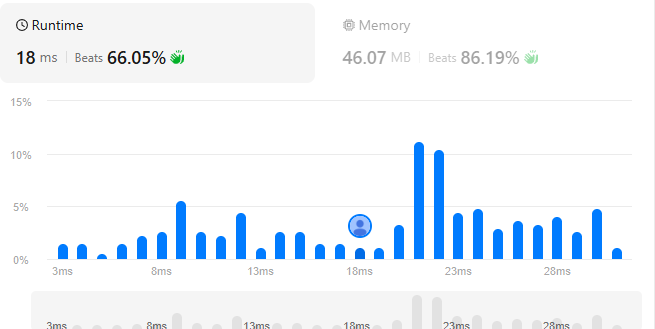